# 04 · Right Decision, Wrong Probability  ·  *the showpiece*

Naive Bayes gets the **class** right remarkably often. Its **probabilities** are almost
useless — pinned near 0 and 1, wildly overconfident. This is the cleanest example in all of
machine learning of a model that makes excellent decisions while producing terrible
probabilities, and this notebook makes it concrete and then shows exactly *why*.

The reason: multiplying many correlated "independent" probabilities compounds the error and
drives the estimate to the extreme. The errors tend to affect all classes similarly, so the
**ranking** (the decision) survives while the **numbers** do not.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src import artifacts
from src.config import SETTINGS
from src.datasets import text, synthetic
from src.evaluation.correlation_effect import overconfidence_vs_correlation
from src.evaluation.probability import calibration_data, log_loss_score, mean_confidence
from src.models import GaussianNB, MultinomialNB
from src.visualisation import plot_calibration, plot_overconfidence_vs_correlation

np.set_printoptions(precision=4, suppress=True)

In [2]:
frame = text.load_text_data()
X, vectorizer = text.vectorize(frame["text"].tolist(), max_features=SETTINGS.text.max_features)
y = frame["label"].to_numpy()

X_tr, X_te, y_tr, y_te, _, txt_te = train_test_split(
    X, y, frame["text"].tolist(), test_size=SETTINGS.test_size,
    stratify=y, random_state=SETTINGS.seed,
)
model = MultinomialNB(alpha=1.0).fit(X_tr, y_tr)
spam_row = int(np.where(model.classes_ == 1)[0][0])
proba = model.predict_proba(X_te)
p_spam = proba[:, spam_row]
preds = model.predict(X_te)
accuracy = float((preds == y_te).mean())
print(f"test accuracy = {accuracy:.4f}")

test accuracy = 0.9857


## 1. The probabilities pile up at the extremes

A well-calibrated classifier would spread its probabilities out. Naive Bayes dumps almost
everything at 0 and 1.

87.9% of test predictions are made with >99% confidence
  P(spam)=1.00000000  |  URGENT!: Your Mobile No. was awarded a Â£2,000 Bonus Ca
  P(spam)=1.00000000  |  This is the 2nd time we have tried 2 contact u. U have 
  P(spam)=1.00000000  |  Spook up your mob with a Halloween collection of a logo


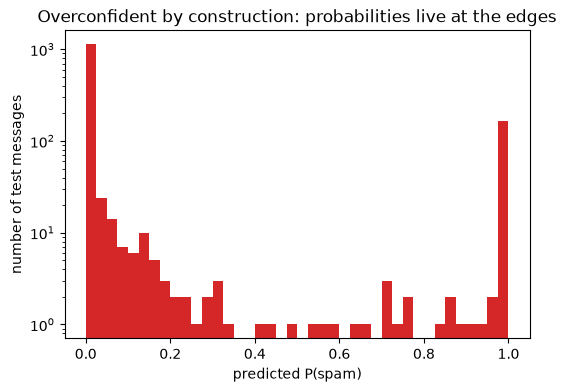

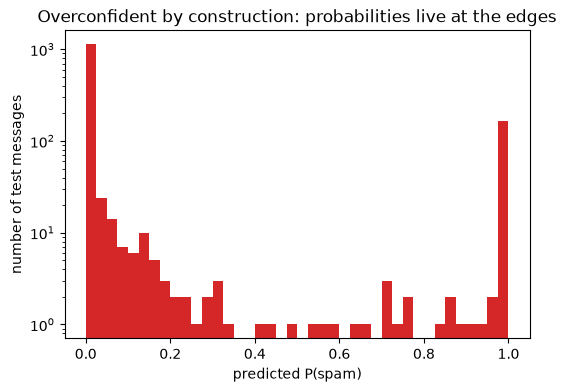

In [3]:
confident = float((np.max(proba, axis=1) > 0.99).mean())
print(f"{confident:.1%} of test predictions are made with >99% confidence")

# Correctly-flagged spam, most extreme first: the model doesn't say 80%, it says 99.99%+.
correct_spam = np.where((y_te == 1) & (preds == 1))[0]
top = correct_spam[np.argsort(p_spam[correct_spam])[::-1][:3]]
examples = []
for i in top:
    print(f"  P(spam)={p_spam[i]:.8f}  |  {txt_te[i][:55]}")
    examples.append({"message": txt_te[i], "p_spam": float(p_spam[i])})

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(p_spam, bins=40, color="tab:red")
ax.set_xlabel("predicted P(spam)")
ax.set_ylabel("number of test messages")
ax.set_title("Overconfident by construction: probabilities live at the edges")
ax.set_yscale("log")
artifacts.save_fig(fig, "04_probability_histogram")
fig

In [4]:
logloss = log_loss_score(y_te, proba)
artifacts.save_json(
    {
        "test_accuracy": accuracy,
        "mean_confidence": mean_confidence(proba),
        "fraction_above_99pct": confident,
        "log_loss": logloss,
        "most_confident_correct_spam": examples,
    },
    "04_overconfidence_spam",
)
print(f"log loss = {logloss:.4f}  (good decisions, but the probabilities are punished)")

log loss = 0.0794  (good decisions, but the probabilities are punished)


## 2. The calibration curve confirms it

A perfectly calibrated model sits on the diagonal: of the messages it calls "70% spam", 70%
really are spam. Naive Bayes bows away from the diagonal and clusters at the corners.

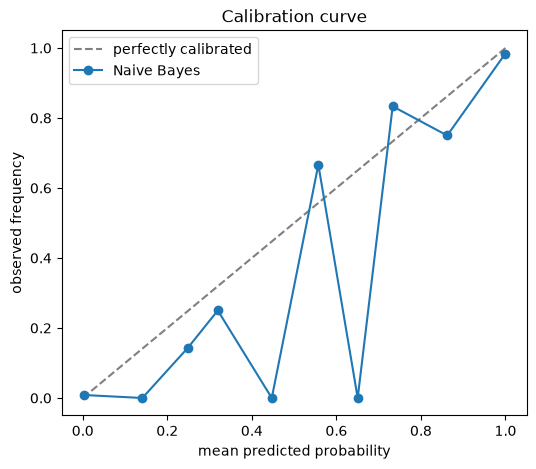

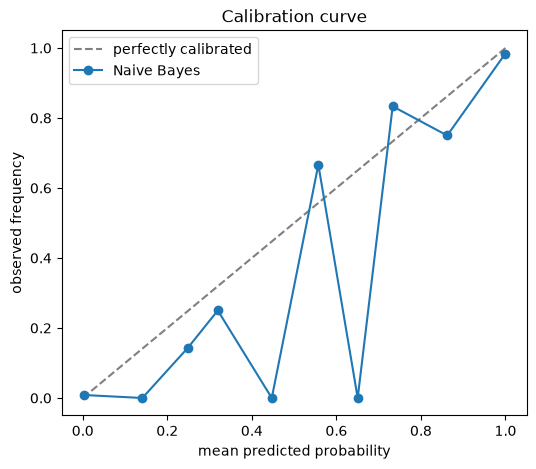

In [5]:
mean_pred, observed = calibration_data(y_te, p_spam, n_bins=10)
fig = plot_calibration(mean_pred, observed)
artifacts.save_fig(fig, "04_calibration_curve")

artifacts.save_json(
    {
        "mean_predicted": mean_pred.tolist(),
        "observed_frequency": observed.tolist(),
        "log_loss": logloss,
    },
    "04_calibration_curve",
)
fig

## 3. The mechanism: double-counted evidence

Why so overconfident? Correlated features violate the independence assumption, and the model
counts the same evidence more than once. The worst case is a **duplicated feature** (perfect
correlation). Here one informative feature decides the class; as we add duplicates, the model
grows more and more certain while its accuracy does not move at all.

  + 0 duplicate(s):  confidence=0.795   accuracy=0.796
  + 1 duplicate(s):  confidence=0.887   accuracy=0.792
  + 2 duplicate(s):  confidence=0.925   accuracy=0.794
  + 4 duplicate(s):  confidence=0.957   accuracy=0.794
  + 8 duplicate(s):  confidence=0.977   accuracy=0.796
  +16 duplicate(s):  confidence=0.988   accuracy=0.797


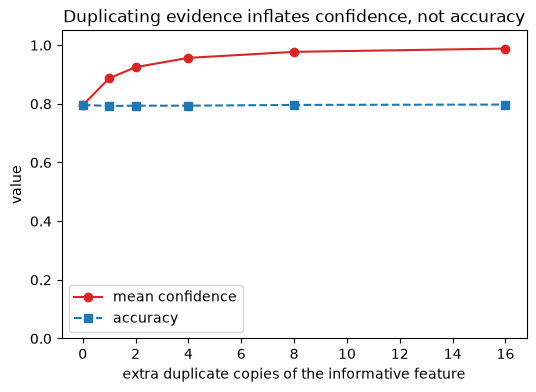

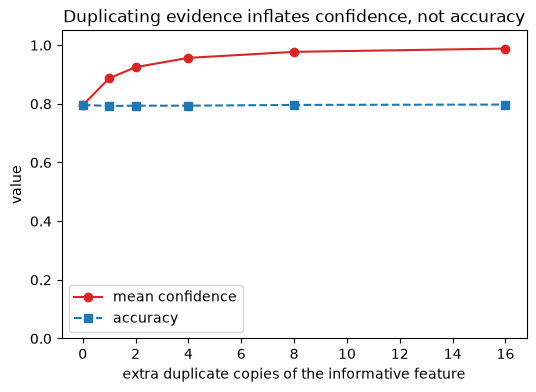

In [6]:
Xi, yi = synthetic.make_informative_plus_noise(n_samples=800, n_noise=3, signal=0.8, seed=0)
copies = [0, 1, 2, 4, 8, 16]
conf, acc = [], []
for c in copies:
    Xc = synthetic.duplicate_feature(Xi, 0, c) if c else Xi
    m = GaussianNB().fit(Xc, yi)
    conf.append(mean_confidence(m.predict_proba(Xc)))
    acc.append(float((m.predict(Xc) == yi).mean()))

for c, cf, ac in zip(copies, conf, acc):
    print(f"  +{c:>2} duplicate(s):  confidence={cf:.3f}   accuracy={ac:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(copies, conf, "o-", label="mean confidence", color="tab:red")
ax.plot(copies, acc, "s--", label="accuracy", color="tab:blue")
ax.set_xlabel("extra duplicate copies of the informative feature")
ax.set_ylabel("value")
ax.set_ylim(0, 1.05)
ax.set_title("Duplicating evidence inflates confidence, not accuracy")
ax.legend()
artifacts.save_fig(fig, "04_duplicated_feature")

artifacts.save_json(
    {"extra_copies": copies, "mean_confidence": conf, "accuracy": acc},
    "04_duplicated_feature",
)
fig

## 4. ...and it scales smoothly with correlation

Duplication is the extreme. The same effect appears as a smooth trend: dial feature
correlation up from 0 to nearly 1 and watch confidence climb while accuracy stays put.

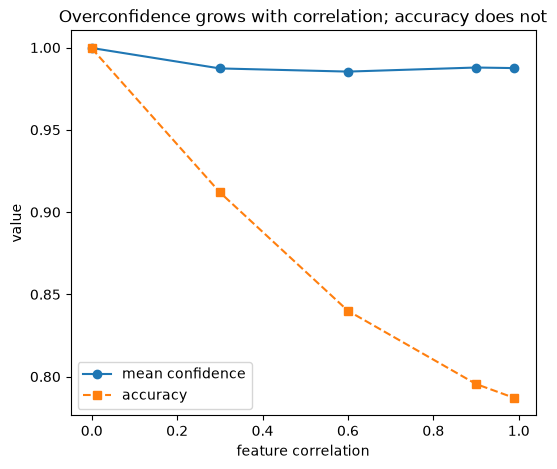

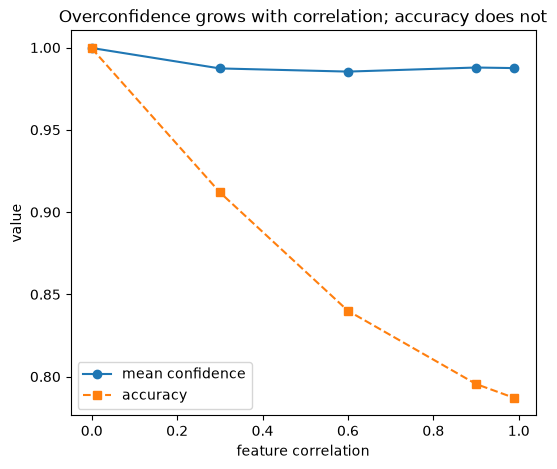

In [7]:
corrs, confidences, accuracies = overconfidence_vs_correlation(
    SETTINGS.synthetic.correlations, n_samples=2000, n_features=20, class_sep=1.5, seed=SETTINGS.seed
)
fig = plot_overconfidence_vs_correlation(corrs, confidences, accuracies)
artifacts.save_fig(fig, "04_overconfidence_vs_correlation")

artifacts.save_json(
    {"correlation": corrs, "mean_confidence": confidences, "accuracy": accuracies},
    "04_overconfidence_vs_correlation",
)
fig

## The lesson (keep this one)

**Getting the class right and getting the probability right are two different things.**
Naive Bayes is the cleanest proof: its decisions are strong, its probabilities are not, and
the gap widens exactly as the independence assumption is violated. Trust its decisions. Do
not trust its probabilities — and if you need calibrated ones, recalibrate (notebook 06).